In [1]:
import os
import re
import numpy as np
from collections import defaultdict

def parse_optics_summary(txt_path="assets/data/optics_summary.txt") -> dict[str, np.ndarray]:
    """
    解析 optics_summary.txt，返回 dict
    
    Returns
    -------
    dict[str, np.ndarray]
        key: sample name (如 'afe_pnma', 'afe_cmcm', 'fe_pnma', 'fe_cmcm')
        value: np.ndarray, shape (N, 3), 列依次为 [波长(nm), n, k]
               按波长升序排列，dtype=float64
    """
    # 匹配 sample 头行: 行首为 sample 名
    sample_pat = re.compile(r"^\s*(afe_pnma|afe_cmcm|fe_pnma|fe_cmcm)\b")
    # 匹配 lambda 行中的波长/n/k
    # e.g. "  lambda  300 nm (E=4.133 eV, nearest 4.132 eV): n_avg=2.0149 k_avg=2.5202 R=..."
    data_pat = re.compile(r"lambda\s+(\d+(?:\.\d+)?)\s*nm.*?n_avg\s*=\s*([0-9.]+).*?k_avg\s*=\s*([0-9.]+)")

    result: dict[str, list] = defaultdict(list)
    current_sample: str | None = None

    with open(txt_path, "r", encoding="utf-8") as f:
        for line in f:
            # 检测是否进入新的 sample 块
            m_sample = sample_pat.match(line)
            if m_sample:
                current_sample = m_sample.group(1)
                continue
            # 在当前 sample 块内解析数据行
            if current_sample:
                m_data = data_pat.search(line)
                if m_data:
                    wl = float(m_data.group(1))
                    n = float(m_data.group(2))
                    k = float(m_data.group(3))
                    result[current_sample].append([wl, n, k])

    # 转为 np.ndarray 并按波长排序
    out: dict[str, np.ndarray] = {}
    for sample, rows in result.items():
        arr = np.array(rows, dtype=np.float64)
        # 按第一列波长排序
        arr = arr[np.argsort(arr[:, 0])]
        out[sample] = arr

    return out

In [2]:
optics_dict = parse_optics_summary(txt_path="assets/data/optics_summary.txt")
for name, arr in optics_dict.items():
    print(f"{name}: shape={arr.shape}")
    print(arr[:3])
    print("...")

afe_pnma: shape=(160, 3)
[[200.       0.8532   1.8752]
 [210.       0.826    1.956 ]
 [220.       0.9246   2.33  ]]
...
afe_cmcm: shape=(160, 3)
[[200.       0.7828   1.5475]
 [210.       0.9374   1.8298]
 [220.       0.9348   1.8339]]
...
fe_pnma: shape=(160, 3)
[[200.       0.8616   1.9872]
 [210.       0.9702   2.0885]
 [220.       0.8153   2.186 ]]
...
fe_cmcm: shape=(160, 3)
[[200.       0.7828   1.5475]
 [210.       0.9374   1.8298]
 [220.       0.9348   1.8339]]
...


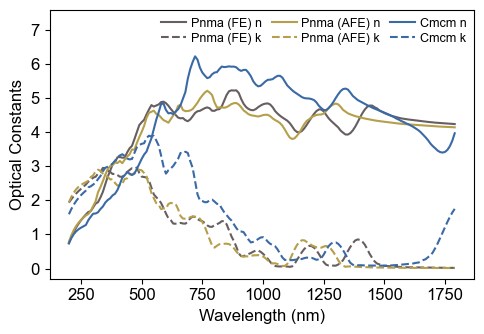

In [7]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
})
colors = ["#675e60", "#b59f4a", "#3a6aa6"]
labels = ["Pnma (FE)", "Pnma (AFE)", "Cmcm"]
fig, ax = plt.subplots(figsize=(5, 3.5))
for key, color, label in zip(["afe_pnma", "fe_pnma", "fe_cmcm"], colors, labels):
    arr = optics_dict[key]
#     ax.plot(arr[::5, 0], arr[::5, 1],
#             color=color, linestyle="None", alpha=0.2, marker="o", markersize=5, markeredgecolor="black", markeredgewidth=0.5)
#     ax.plot(arr[::5, 0], arr[::5, 2],
#             color=color, linestyle="None", alpha=0.2, marker="s", markersize=5, markeredgecolor="black", markeredgewidth=0.5)
    smooth_n = savgol_filter(arr[:, 1], window_length=15, polyorder=3)
    smooth_k = savgol_filter(arr[:, 2], window_length=15, polyorder=3)
    ax.plot(arr[:, 0], smooth_n, color=color, alpha=1, linestyle="-", label=f"{label} n")  # type: ignore
    ax.plot(arr[:, 0], smooth_k, color=color, alpha=1, linestyle="--", label=f"{label} k")  # type: ignore
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Optical Constants")
ax.legend(
    loc="upper right",
    ncol=3,
    frameon=False,
    fontsize=9,
    columnspacing=0.8,
    handletextpad=0.35,
    labelspacing=0.25,
    borderaxespad=0.2,
)
ax.set_ylim(None, 7.6)
# Get the n and k at 800 nm for each sample
pnma_fe_800 = optics_dict["fe_pnma"][optics_dict["fe_pnma"][:, 0] == 800][0, 1:3]
pnma_afe_800 = optics_dict["afe_pnma"][optics_dict["afe_pnma"][:, 0] == 800][0, 1:3]
cmcm_800 = optics_dict["fe_cmcm"][optics_dict["fe_cmcm"][:, 0] == 800][0, 1:3]
# ax.text(0.6, 0.28, f"At 800 nm:\nPnma (FE): n = {pnma_fe_800[0]:.1f}, k = {pnma_fe_800[1]:.1f}\nPnma (AFE): n = {pnma_afe_800[0]:.1f}, k = {pnma_afe_800[1]:.1f}\nCmcm: n = {cmcm_800[0]:.1f}, k = {cmcm_800[1]:.1f}",
#         transform=ax.transAxes)
fig.tight_layout()
fig.savefig("assets/figure/snse_optical_constants.png", dpi=600)